# Vehicle Image Classification: MobileNetV2 (end to end)

Three classes: **airplanes / cars / ship**. Companion notebook to
`vehicle_classification_efficientnetb0.ipynb`, using the same dataset and
methodology but swapping the backbone to **MobileNetV2** for comparison.

This notebook imports the shared pipeline from the `vehicle_classifier`
package (`src/vehicle_classifier/`) instead of duplicating it, so the two
notebooks can never drift out of sync on data loading/cleaning/splitting.

**Note on the dataset:** there are only 48 images (16 per class), so the
accuracy numbers here are estimates from a 9-image test set and should not
be read as a reliable score. The 5-fold cross-validation cell gives a
steadier number. Two known data issues are flagged in the EDA section.

## 1. Setup

In [1]:
import json
import random

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (classification_report, confusion_matrix,
                              ConfusionMatrixDisplay, roc_auc_score, roc_curve, auc)
from sklearn.preprocessing import label_binarize

from vehicle_classifier.config import (
    CLASS_NAMES_PATH, DATA_ROOT, IMG_SIZE, SEED,
    model_path, best_head_path, best_finetuned_path,
)
from vehicle_classifier.data import discover_classes, load_and_clean, make_dataset, stratified_split
from vehicle_classifier.model import build_model, unfreeze_for_finetuning, build_augmentation, LAST_CONV_LAYER
from vehicle_classifier.train import set_seeds
from vehicle_classifier.evaluate import evaluate
from vehicle_classifier.gradcam import gradcam_heatmap
from vehicle_classifier.predict import VehicleClassifier

ARCHITECTURE = "mobilenetv2"

set_seeds(SEED)
sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU: []


## 2. Load the data

Reuses `vehicle_classifier.data.load_and_clean`, the same cleaning/loading
code the EfficientNetB0 notebook and the `train.py` script both use. Expects
`data/vehicles/<class>/*.jpg` relative to the project root (see
`vehicle_classifier.config.DATA_ROOT`).

In [2]:
CLASS_NAMES = discover_classes(DATA_ROOT)
NUM_CLASSES = len(CLASS_NAMES)
print("classes:", CLASS_NAMES)
for c in CLASS_NAMES:
    print(f"  {c:12s} {len(list((DATA_ROOT / c).glob('*'))):4d} files")

classes: ['airplanes', 'cars', 'ship']
  airplanes      16 files
  cars           16 files
  ship           16 files


## 3. Cleaning

`load_and_clean` runs four checks, each of which silently poisons training
if skipped:
1. **Corrupt/truncated files** - `PIL.verify()` catches these before they reach `tf.data`.
2. **Exact duplicates** - MD5 hash. A duplicate that lands in both train and test leaks the label.
3. **Non-RGB modes** - everything is converted to RGB.
4. **Degenerate images** - anything smaller than 32px on a side is dropped.

In [3]:
df = load_and_clean(DATA_ROOT, class_names=CLASS_NAMES)
df.head()

kept 48 images | dropped: 0 corrupt, 0 duplicate, 0 tiny


,path,cls,label,width,height,mode,aspect,kb,mean_px,std_px
0,E:\mywork\repo\classificaion\data\vehicles\air...,airplanes,0,1200,1200,RGB,1.0,100.525391,121.102545,48.272025
1,E:\mywork\repo\classificaion\data\vehicles\air...,airplanes,0,1200,1200,RGB,1.0,83.518555,120.125432,52.776925
2,E:\mywork\repo\classificaion\data\vehicles\air...,airplanes,0,1200,1200,RGB,1.0,31.551758,96.852399,46.524238
3,E:\mywork\repo\classificaion\data\vehicles\air...,airplanes,0,1200,1200,RGB,1.0,73.324219,175.676736,39.280886
4,E:\mywork\repo\classificaion\data\vehicles\air...,airplanes,0,1200,1200,RGB,1.0,63.418945,110.385744,56.576269


## 4. Exploratory data analysis

In [4]:
print("class balance")
print(df["cls"].value_counts().to_string())
print("\ncolour modes:", df["mode"].value_counts().to_dict())
print("\nnumeric summary")
display(df.groupby("cls")[["width", "height", "aspect", "kb", "mean_px", "std_px"]]
          .agg(["mean", "min", "max"]).round(1))

class balance


cls
airplanes    16
cars         16
ship         16

colour modes: {'RGB': 48}

numeric summary


width              height             aspect               kb  \
             mean   min   max    mean   min   max   mean  min  max   mean   
cls                                                                         
airplanes  1200.0  1200  1200  1200.0  1200  1200    1.0  1.0  1.0   99.5   
cars       1200.0  1200  1200  1200.0  1200  1200    1.0  1.0  1.0  136.6   
ship        210.0   210   210   143.9   118   158    1.5  1.3  1.8    9.9   

                       mean_px              std_px               
            min    max    mean   min    max   mean   min    max  
cls                                                              
airplanes  31.6  245.4   136.3  49.5  192.7   52.8  36.0   88.7  
cars       79.4  261.1    99.3  42.4  157.1   71.8  56.2  102.7  
ship        6.1   15.9   138.1  84.4  190.0   62.2  32.7   82.1

C:\Users\MSI MODERN\AppData\Local\Temp\ipykernel_9036\3710335153.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="cls", order=CLASS_NAMES, ax=ax[0, 0], palette="deep")
C:\Users\MSI MODERN\AppData\Local\Temp\ipykernel_9036\3710335153.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="cls", y="kb", order=CLASS_NAMES, ax=ax[1, 1], palette="deep")


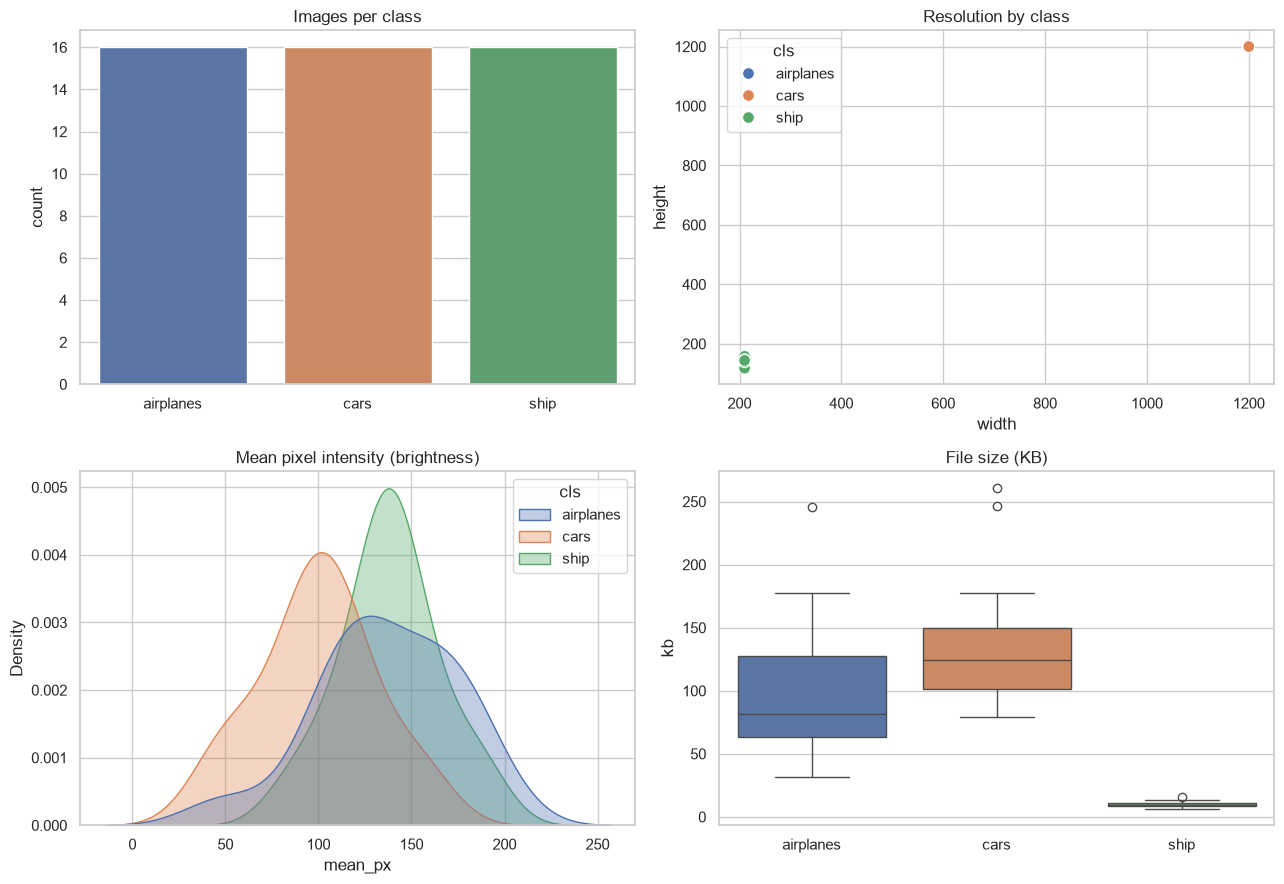

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
sns.countplot(data=df, x="cls", order=CLASS_NAMES, ax=ax[0, 0], palette="deep")
ax[0, 0].set_title("Images per class"); ax[0, 0].set_xlabel("")
sns.scatterplot(data=df, x="width", y="height", hue="cls", s=70, ax=ax[0, 1])
ax[0, 1].set_title("Resolution by class")
sns.kdeplot(data=df, x="mean_px", hue="cls", fill=True, alpha=.35, ax=ax[1, 0])
ax[1, 0].set_title("Mean pixel intensity (brightness)")
sns.boxplot(data=df, x="cls", y="kb", order=CLASS_NAMES, ax=ax[1, 1], palette="deep")
ax[1, 1].set_title("File size (KB)"); ax[1, 1].set_xlabel("")
plt.tight_layout(); plt.show()

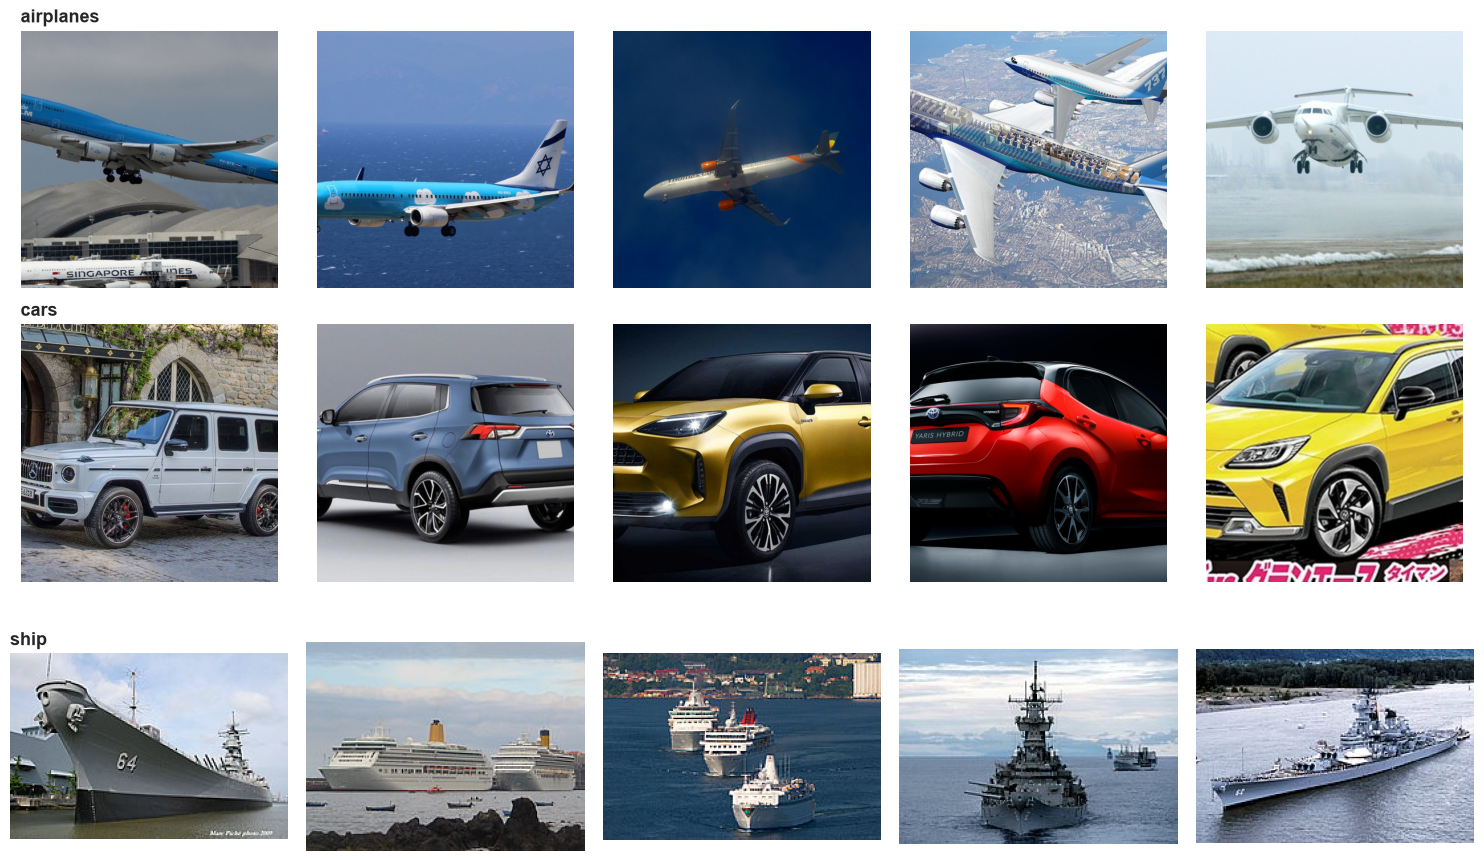

In [6]:
# sample grid: 5 random images per class
N_SHOW = 5
fig, axes = plt.subplots(NUM_CLASSES, N_SHOW, figsize=(3 * N_SHOW, 3 * NUM_CLASSES))
axes = np.atleast_2d(axes)
for i, cls in enumerate(CLASS_NAMES):
    sub = df[df.cls == cls].sample(min(N_SHOW, (df.cls == cls).sum()), random_state=SEED)
    for j, (_, r) in enumerate(sub.iterrows()):
        axes[i, j].imshow(Image.open(r.path).convert("RGB")); axes[i, j].axis("off")
    axes[i, 0].set_title(cls, loc="left", fontsize=13, fontweight="bold")
    for j in range(len(sub), N_SHOW):
        axes[i, j].axis("off")
plt.tight_layout(); plt.show()

### EDA findings

Same two issues as the EfficientNetB0 notebook, since this is the same
dataset:

**1. Resolution is a giveaway.** All airplane and car images are exactly
1200x1200. All ship images are 210 wide and 118-158 tall, roughly 10 KB each
versus 100-137 KB for the other two classes. After resizing to 224x224 the
ship images carry visible upscaling blur the other classes do not, so a
model can learn *"blurry means ship"* rather than learning what a ship
looks like. Fix: source all three classes at comparable resolution.

**2. The dataset is tiny.** 16 images per class leaves about 10 per class
for training and 9 images total in the test split, so a single
misclassification moves accuracy by about 11 points. Treat the
cross-validation number as the real estimate.

## 5. Stratified train / validation / test split

`stratified_split` keeps all three classes proportionally represented in
each split, using the same split ratios and `SEED` as the EfficientNetB0
notebook and `train.py`, so results are directly comparable.

In [7]:
(p_train, y_train), (p_val, y_val), (p_test, y_test) = stratified_split(df)
for name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:6s} n={len(y):3d}  per class: "
          f"{dict(zip(CLASS_NAMES, np.bincount(y, minlength=NUM_CLASSES)))}")

train  n= 30  per class: {'airplanes': np.int64(10), 'cars': np.int64(10), 'ship': np.int64(10)}
val    n=  9  per class: {'airplanes': np.int64(3), 'cars': np.int64(3), 'ship': np.int64(3)}
test   n=  9  per class: {'airplanes': np.int64(3), 'cars': np.int64(3), 'ship': np.int64(3)}


## 6. Preprocessing and `tf.data` input pipeline

**MobileNetV2-specific detail worth knowing:** unlike EfficientNetB0 (which
bakes normalisation into its graph and wants raw 0-255 pixels), MobileNetV2
expects pixels scaled to **[-1, 1]**. Rather than special-casing the data
pipeline, `vehicle_classifier.model.build_model` adds that rescaling as a
`Rescaling` layer *inside* the model graph (see `model.py`). So the exact
same `make_dataset` pipeline below, producing raw 0-255 float32 images,
works unmodified for either architecture - the saved `.keras` file is
self-contained and handles its own normalisation.

Augmentation runs only on the training set, and only during training
(`training=True`).

In [8]:
train_ds = make_dataset(p_train, y_train, shuffle=True)
val_ds   = make_dataset(p_val,   y_val)
test_ds  = make_dataset(p_test,  y_test)

data_augmentation = build_augmentation()

xb, yb = next(iter(train_ds))
print("batch:", xb.shape, xb.dtype, "| pixel range:",
      float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)))

batch: (8, 224, 224, 3) <dtype: 'float32'> | pixel range: 0.0 - 255.0


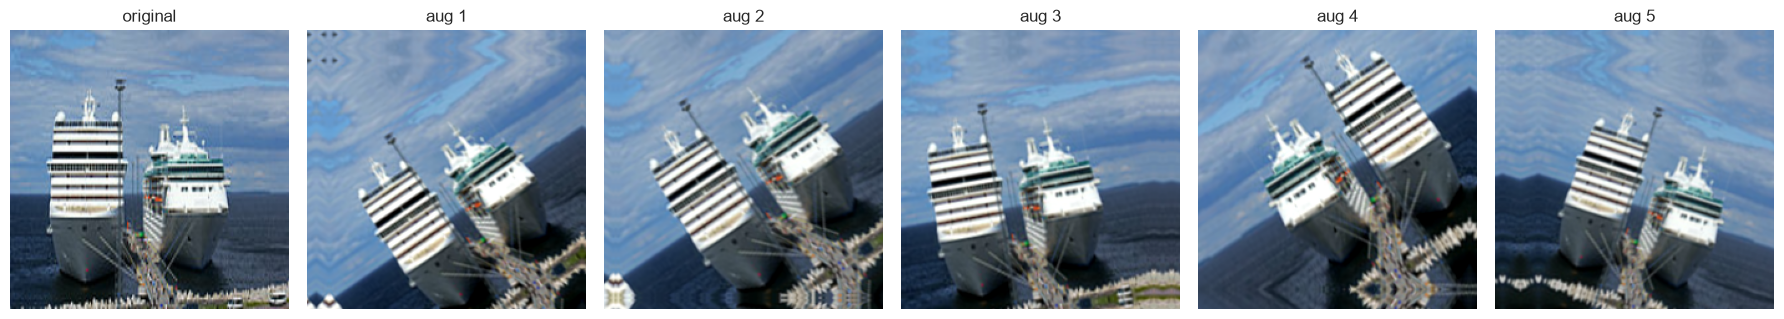

In [9]:
# what augmentation actually does to one image
img = xb[0:1]
fig, axes = plt.subplots(1, 6, figsize=(18, 3.2))
axes[0].imshow(tf.cast(img[0], tf.uint8)); axes[0].set_title("original"); axes[0].axis("off")
for i in range(1, 6):
    aug = data_augmentation(img, training=True)
    axes[i].imshow(tf.cast(tf.clip_by_value(aug[0], 0, 255), tf.uint8))
    axes[i].set_title(f"aug {i}"); axes[i].axis("off")
plt.tight_layout(); plt.show()

## 7. Model: MobileNetV2 transfer learning

Stage 1 freezes the entire ImageNet backbone and trains only a small
classification head. With about 30 training images, training the full
backbone from the start would overfit instantly - the same reasoning as the
EfficientNetB0 notebook, just with a smaller, faster backbone.

In [10]:
model, base_model = build_model(ARCHITECTURE, num_classes=NUM_CLASSES)
print(f"total params      {model.count_params():,}")
print(f"trainable params  {sum(np.prod(w.shape) for w in model.trainable_weights):,}")
model.summary(show_trainable=True)

E:\mywork\repo\classificaion\src\vehicle_classifier\model.py:59: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = _BACKBONE_BUILDERS[architecture](


total params      2,266,947
trainable params  6,403


Model: "mobilenetv2_vehicles"

┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)      ┃ Output Shape    ┃   Param # ┃ Connected to   ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_1     │ (None, 224,     │         0 │ -              │   -   │
│ (InputLayer)      │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ data_augmentation │ (None, 224,     │         0 │ input_layer_1… │   -   │
│ (Sequential)      │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ mobilenetv2_resc… │ (None, 224,     │         0 │ data_augmenta… │   -   │
│ (Rescaling)       │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ Conv1 (Conv2D)    │ (None, 112,     │       864 │ mobilenetv2_r… │   N   │
│                   │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ bn_Conv1          │ (None, 112,     │       128 │ Conv1[0][0]    │   N   │
│ (BatchNormalizat… │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ Conv1_relu (ReLU) │ (None, 112,     │         0 │ bn_Conv1[0][0] │   -   │
│                   │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ expanded_conv_de… │ (None, 112,     │       288 │ Conv1_relu[0]… │   N   │
│ (DepthwiseConv2D) │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ expanded_conv_de… │ (None, 112,     │       128 │ expanded_conv… │   N   │
│ (BatchNormalizat… │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ expanded_conv_de… │ (None, 112,     │         0 │ expanded_conv… │   -   │
│ (ReLU)            │ 112, 32)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ expanded_conv_pr… │ (None, 112,     │       512 │ expanded_conv… │   N   │
│ (Conv2D)          │ 112, 16)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ expanded_conv_pr… │ (None, 112,     │        64 │ expanded_conv… │   N   │
│ (BatchNormalizat… │ 112, 16)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block_1_expand    │ (None, 112,     │     1,536 │ expanded_conv… │   N   │
│ (Conv2D)          │ 112, 96)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block_1_expand_BN │ (None, 112,     │       384 │ block_1_expan… │   N   │
│ (BatchNormalizat… │ 112, 96)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block_1_expand_r… │ (None, 112,     │         0 │ block_1_expan… │   -   │
│ (ReLU)            │ 112, 96)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block_1_pad       │ (None, 113,     │         0 │ block_1_expan… │   -   │
│ (ZeroPadding2D)   │ 113, 96)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block_1_depthwise │ (None, 56, 56,  │       864 │ block_1_pad[0… │   N   │
│ (DepthwiseConv2D) │ 96)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ block_1_depthwis… │ (None, 56, 56,  │       384 │ block_1_depth… │   N 

 Total params: 2,266,947 (8.65 MB)

 Trainable params: 6,403 (25.01 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [11]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=12,
                                   restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                       patience=5, min_lr=1e-6, verbose=1),
    keras.callbacks.ModelCheckpoint(str(best_head_path(ARCHITECTURE)), monitor="val_accuracy",
                                     save_best_only=True, verbose=0),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=40,
                     callbacks=callbacks, verbose=1)

Epoch 1/40


C:\Users\MSI MODERN\miniconda3\envs\myml\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1/4 ━━━━━━━━━━━━━━━━━━━━ 17s 6s/step - accuracy: 0.7500 - loss: 1.1773

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 316ms/step - accuracy: 0.6875 - loss: 1.3078

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 314ms/step - accuracy: 0.6250 - loss: 1.2162

...

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step - accuracy: 1.0000 - loss: 0.0024

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 1.0000 - loss: 0.0032

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step - accuracy: 1.0000 - loss: 0.0028

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 310ms/step - accuracy: 1.0000 - loss: 0.0028 - val_accuracy: 1.0000 - val_loss: 0.0093 - learning_rate: 0.0010


Restoring model weights from the end of the best epoch: 38.


### Stage 2: fine-tuning

Unfreeze the top block of the backbone and continue at a much lower
learning rate. `unfreeze_for_finetuning` keeps all `BatchNormalization`
layers frozen on purpose: with a batch size of 8, recomputing batch
statistics destabilises the pretrained features.

In [12]:
unfreeze_for_finetuning(model, base_model, num_unfrozen_layers=20, learning_rate=1e-5)
print(f"trainable params now {sum(np.prod(w.shape) for w in model.trainable_weights):,}")

history_ft = model.fit(
    train_ds, validation_data=val_ds, epochs=20,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=8,
                                       restore_best_weights=True, verbose=1),
        keras.callbacks.ModelCheckpoint(str(best_finetuned_path(ARCHITECTURE)), monitor="val_accuracy",
                                         save_best_only=True, verbose=0),
    ],
    verbose=1,
)

trainable params now 1,201,283
Epoch 1/20


1/4 ━━━━━━━━━━━━━━━━━━━━ 28s 9s/step - accuracy: 1.0000 - loss: 6.1162e-04

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 219ms/step - accuracy: 1.0000 - loss: 0.0249  

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - accuracy: 1.0000 - loss: 0.0222

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 1.0000 - loss: 0.0217

...

2/4 ━━━━━━━━━━━━━━━━━━━━ 0s 230ms/step - accuracy: 1.0000 - loss: 0.0015    

3/4 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step - accuracy: 1.0000 - loss: 0.0012

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 1.0000 - loss: 0.0014

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 303ms/step - accuracy: 1.0000 - loss: 0.0014 - val_accuracy: 1.0000 - val_loss: 0.0030


Restoring model weights from the end of the best epoch: 16.


## 8. Evaluation

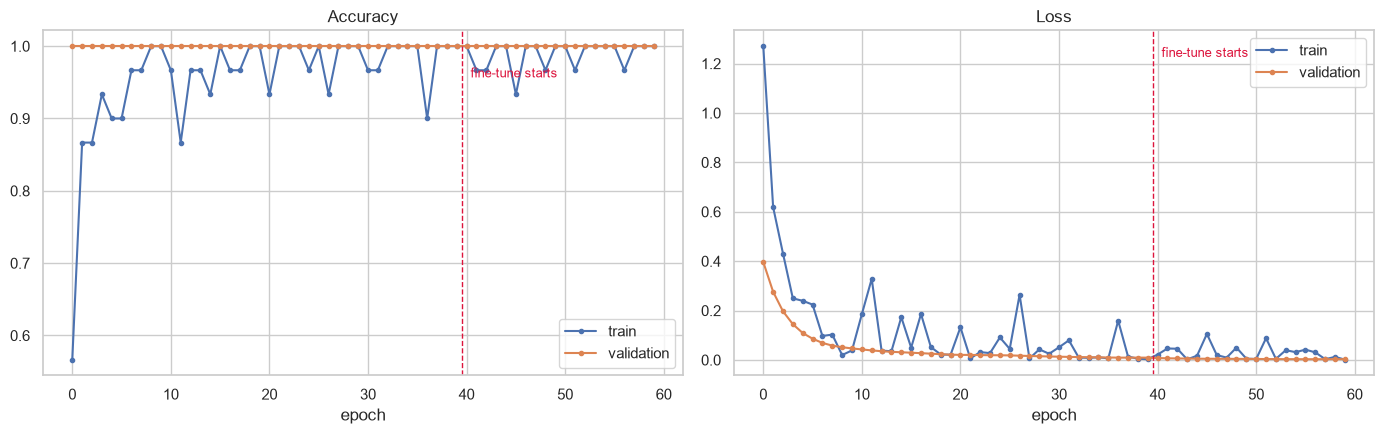

In [13]:
def merge(h1, h2, key):
    return list(h1.history.get(key, [])) + list(h2.history.get(key, []))

split_at = len(history.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for i, (k, vk, title) in enumerate([("accuracy", "val_accuracy", "Accuracy"),
                                     ("loss", "val_loss", "Loss")]):
    ax[i].plot(merge(history, history_ft, k),  marker="o", ms=3, label="train")
    ax[i].plot(merge(history, history_ft, vk), marker="o", ms=3, label="validation")
    ax[i].axvline(split_at - 0.5, color="crimson", ls="--", lw=1)
    ax[i].text(split_at, ax[i].get_ylim()[1] * 0.95, " fine-tune starts",
               color="crimson", fontsize=9, va="top")
    ax[i].set_title(title); ax[i].set_xlabel("epoch"); ax[i].legend()
plt.tight_layout(); plt.show()

In [14]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
y_proba = model.predict(test_ds, verbose=0)
y_pred  = y_proba.argmax(axis=1)
y_true  = np.concatenate([y.numpy() for _, y in test_ds])

print(f"Test loss     {test_loss:.4f}")
print(f"Test accuracy {test_acc:.4f}   ({(y_pred == y_true).sum()}/{len(y_true)} correct)")
print("\n" + classification_report(y_true, y_pred, target_names=CLASS_NAMES,
                                     digits=3, zero_division=0))

Test loss     0.0025
Test accuracy 1.0000   (9/9 correct)

              precision    recall  f1-score   support

   airplanes      1.000     1.000     1.000         3
        cars      1.000     1.000     1.000         3
        ship      1.000     1.000     1.000         3

    accuracy                          1.000         9
   macro avg      1.000     1.000     1.000         9
weighted avg      1.000     1.000     1.000         9



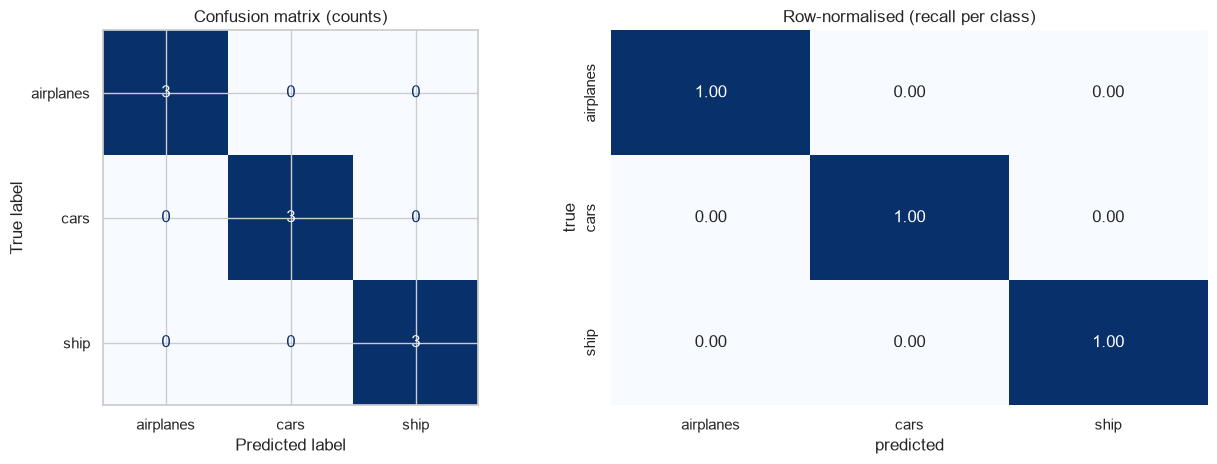

In [15]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(
    ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ax[0].set_title("Confusion matrix (counts)")
cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", cbar=False,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax[1], vmin=0, vmax=1)
ax[1].set_title("Row-normalised (recall per class)")
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("true")
plt.tight_layout(); plt.show()

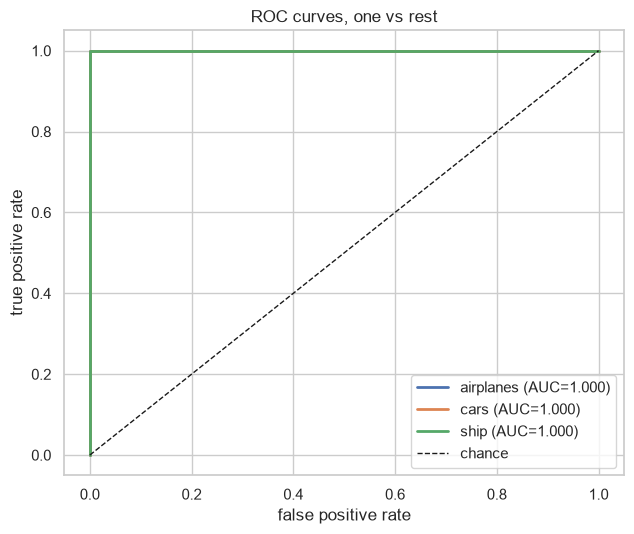

macro ROC-AUC: 1.0


In [16]:
# one-vs-rest ROC curves
y_bin = label_binarize(y_true, classes=range(NUM_CLASSES))
plt.figure(figsize=(6.5, 5.5))
for i, cls in enumerate(CLASS_NAMES):
    if y_bin[:, i].sum() == 0:
        continue
    fpr, tpr, _ = roc_curve(y_bin[:, i], y_proba[:, i])
    plt.plot(fpr, tpr, lw=2, label=f"{cls} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="chance")
plt.xlabel("false positive rate"); plt.ylabel("true positive rate")
plt.title("ROC curves, one vs rest"); plt.legend(loc="lower right")
plt.tight_layout(); plt.show()

try:
    print("macro ROC-AUC:", round(roc_auc_score(y_true, y_proba, multi_class="ovr",
                                                 average="macro"), 4))
except ValueError as e:
    print("macro ROC-AUC unavailable (a class is missing from the test split):", e)

In [17]:
# misclassified images (if any)
test_imgs = np.concatenate([x.numpy() for x, _ in test_ds])
wrong = np.where(y_pred != y_true)[0]
if len(wrong) == 0:
    print("No misclassifications on the test set.")
else:
    n = len(wrong)
    fig, axes = plt.subplots(1, n, figsize=(3.4 * n, 3.8), squeeze=False)
    for k, i in enumerate(wrong):
        axes[0][k].imshow(test_imgs[i].astype("uint8")); axes[0][k].axis("off")
        axes[0][k].set_title(f"true: {CLASS_NAMES[y_true[i]]}\n"
                              f"pred: {CLASS_NAMES[y_pred[i]]} ({y_proba[i].max():.2f})",
                              fontsize=10, color="crimson")
    plt.suptitle(f"{n} misclassified", y=1.03)
    plt.tight_layout(); plt.show()

No misclassifications on the test set.


## 9. Grad-CAM: what the model is actually looking at

Uses `vehicle_classifier.gradcam.gradcam_heatmap` against MobileNetV2's
last conv activation (`LAST_CONV_LAYER["mobilenetv2"]`, i.e. `out_relu`)
rather than EfficientNetB0's `top_conv`. Given the resolution confound
flagged in the EDA, this tells you whether the model is attending to the
*object* or to background and compression artefacts. Heat on the hull,
wings or wheels is a good sign; heat spread flatly over the sky or water is
a warning.

C:\Users\MSI MODERN\miniconda3\envs\myml\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_6']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


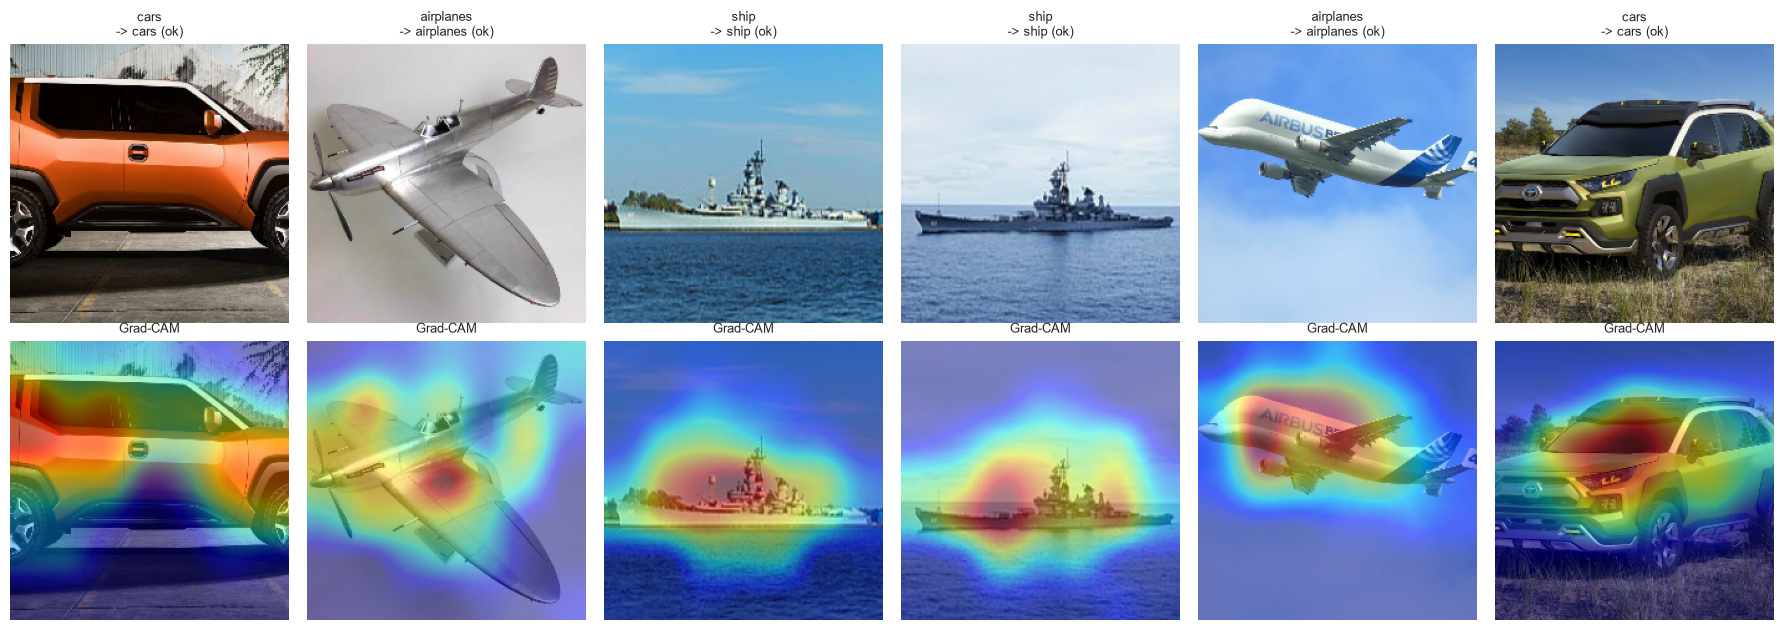

In [18]:
last_conv_layer_name = LAST_CONV_LAYER[ARCHITECTURE]
n_show = min(6, len(test_imgs))
fig, axes = plt.subplots(2, n_show, figsize=(3 * n_show, 6.4))
axes = np.atleast_2d(axes)
for i in range(n_show):
    raw = test_imgs[i]
    heat = gradcam_heatmap(raw[None, ...], model, last_conv_layer_name)
    heat_rs = np.array(Image.fromarray(np.uint8(255 * heat)).resize((IMG_SIZE, IMG_SIZE)))
    ok = "ok" if y_pred[i] == y_true[i] else "WRONG"
    axes[0, i].imshow(raw.astype("uint8")); axes[0, i].axis("off")
    axes[0, i].set_title(f"{CLASS_NAMES[y_true[i]]}\n-> {CLASS_NAMES[y_pred[i]]} ({ok})",
                          fontsize=9)
    axes[1, i].imshow(raw.astype("uint8"))
    axes[1, i].imshow(heat_rs, cmap="jet", alpha=0.45); axes[1, i].axis("off")
    axes[1, i].set_title("Grad-CAM", fontsize=9)
plt.tight_layout(); plt.show()

## 10. 5-fold stratified cross-validation

With a 9-image test set, a single split tells you very little.
Cross-validation reuses every image as test data exactly once and reports
mean and spread, which is the number to quote. This retrains the model
five times. Set `RUN_CV = False` to skip.

E:\mywork\repo\classificaion\src\vehicle_classifier\model.py:59: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = _BACKBONE_BUILDERS[architecture](


C:\Users\MSI MODERN\miniconda3\envs\myml\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


fold 1: accuracy 1.000  (n_test=10)


fold 2: accuracy 1.000  (n_test=10)


fold 3: accuracy 0.900  (n_test=10)


fold 4: accuracy 1.000  (n_test=9)


fold 5: accuracy 1.000  (n_test=9)

5-fold CV accuracy: 0.980 +/- 0.040


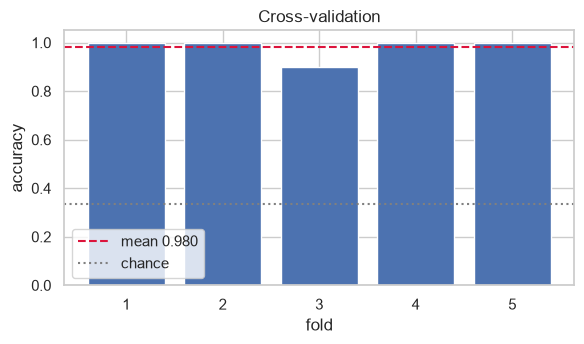

In [19]:
RUN_CV = True
if RUN_CV:
    paths, labels = df["path"].values, df["label"].values
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    fold_scores = []
    for fold, (tr_idx, te_idx) in enumerate(skf.split(paths, labels), start=1):
        keras.backend.clear_session(); set_seeds(SEED)
        m, _ = build_model(ARCHITECTURE, num_classes=NUM_CLASSES)
        m.fit(make_dataset(paths[tr_idx], labels[tr_idx], shuffle=True),
              epochs=25, verbose=0)
        acc = m.evaluate(make_dataset(paths[te_idx], labels[te_idx]), verbose=0)[1]
        fold_scores.append(acc)
        print(f"fold {fold}: accuracy {acc:.3f}  (n_test={len(te_idx)})")

    print(f"\n5-fold CV accuracy: {np.mean(fold_scores):.3f} "
          f"+/- {np.std(fold_scores):.3f}")

    plt.figure(figsize=(6, 3.6))
    plt.bar(range(1, 6), fold_scores, color="#4C72B0")
    plt.axhline(np.mean(fold_scores), color="crimson", ls="--",
                label=f"mean {np.mean(fold_scores):.3f}")
    plt.axhline(1 / NUM_CLASSES, color="gray", ls=":", label="chance")
    plt.ylim(0, 1.05); plt.xlabel("fold"); plt.ylabel("accuracy")
    plt.title("Cross-validation"); plt.legend(); plt.tight_layout(); plt.show()
else:
    print("cross-validation skipped")

## 11. Save the model and run inference on a new image

saved E:\mywork\repo\classificaion\models\vehicle_classifier_mobilenetv2.keras


cars (100.0%)
  cars         100.00%
  ship          0.00%
  airplanes     0.00%


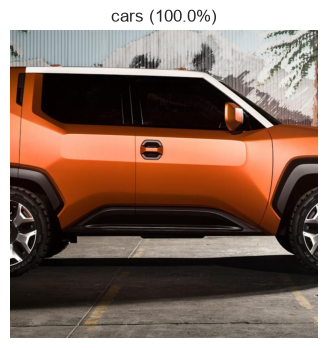

In [20]:
model.save(model_path(ARCHITECTURE))
with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(CLASS_NAMES, f)
print("saved", model_path(ARCHITECTURE))

# --- reload through the same VehicleClassifier a future FastAPI service would use ---
clf = VehicleClassifier(architecture=ARCHITECTURE)
label, confidence = clf.predict(p_test[0])
print(f"{label} ({confidence:.1%})")
for c, p in sorted(clf.predict_proba(p_test[0]).items(), key=lambda t: -t[1]):
    print(f"  {c:12s} {p:6.2%}")

plt.figure(figsize=(4, 4))
plt.imshow(Image.open(p_test[0]).convert("RGB")); plt.axis("off")
plt.title(f"{label} ({confidence:.1%})")
plt.show()

## 12. Head-to-head: MobileNetV2 vs EfficientNetB0

Both architectures were trained with the identical pipeline, split and
seed, so their test-set and cross-validation numbers are directly
comparable. This re-evaluates both from their saved `.keras` files
(equivalent to running `python -m vehicle_classifier.compare`).

In [21]:
comparison_rows = []
for arch in ["efficientnetb0", "mobilenetv2"]:
    if not model_path(arch).exists():
        print(f"skipping {arch}: no trained model found at {model_path(arch)}")
        continue
    r = evaluate(arch, DATA_ROOT)
    comparison_rows.append({
        "architecture": arch,
        "params": r["num_params"],
        "test_accuracy": round(r["test_accuracy"], 4),
        "test_loss": round(r["test_loss"], 4),
        "macro_roc_auc": round(r["macro_roc_auc"], 4) if r["macro_roc_auc"] is not None else None,
    })

comparison_df = pd.DataFrame(comparison_rows).set_index("architecture")
display(comparison_df)

,params,test_accuracy,test_loss,macro_roc_auc
architecture,,,,
efficientnetb0,4058534,1.0,0.0019,1.0
mobilenetv2,2266947,1.0,0.0025,1.0


## Next steps

- **More data.** 16 images per class is the binding constraint for both
  architectures.
- **Fix the resolution confound.** Re-source the ship images at the same
  resolution as airplanes and cars.
- **Pick a winner for serving.** Weigh the 5-fold CV accuracy from section 10
  against model size/inference latency from section 12 to decide which
  architecture the future FastAPI service should load by default.
- **Add classes.** `discover_classes` reads folder names under
  `data/vehicles/`, so dropping in a `motorcycles/` folder needs no code
  changes in either notebook.